In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

#Topology

In [ ]:
from google.colab import drive
import pandas as pd
drive.mount('/content/gdrive')

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [ ]:
df_ref = pd.read_csv("/content/gdrive/MyDrive/New_Repo_Data/ref_features_nodes_in_graph_iid.csv")
from sklearn.preprocessing import StandardScaler

# Exclude non-numeric/id/label columns from normalization
features = df_ref.select_dtypes(include=['number']).columns.tolist()
features = [col for col in features if col.lower() not in ['Node', 'label']]

# scaler = StandardScaler()
# df_ref[features] = scaler.fit_transform(df_ref[features])

data = pd.read_csv('/content/gdrive/MyDrive/New_Repo_Data/embeddings_mean_protbert_3k.csv')
data.columns.values[0] = "Node"
label_data = data[['Node','label']]
ref_df = pd.merge(df_ref, label_data, on='Node', how='inner')
ref_df.rename(columns={ref_df.columns[0]: 'id'}, inplace=True)
df = ref_df

In [ ]:
df

,id,Average Shortest Path Length,Betweenness Centrality,Closeness Centrality,Clustering Coefficient,Degree,Eccentricity,Neighborhood Connectivity,Number of Undirected Edges,Partner of Multi-Edged Node Pairs,Radiality,Self Loops,Stress Centrality,Topological Coefficient,Number of directed Edges,proportion_links_to_disease_proteins,proportion_links_second_neighbors,communication_efficiency,positive_topology_coefficient,label
0,A4D2B8,2.423057,0.424165,0.322346,0.333333,5,5,60.600000,5,0,0.20,0,4518.848330,0.800000,0,0.600000,0.513294,985.850000,2.000000,1
1,A6NDG6,2.423057,2.473814,0.370358,0.066667,8,4,293.125000,8,0,0.25,0,4522.947629,0.500000,0,0.625000,0.534061,1135.666667,2.500000,1
2,A0A087WXM9,2.423057,39.688022,0.381878,0.228571,15,4,269.866667,15,0,0.25,0,4597.376045,0.228571,0,0.533333,0.566711,1178.833333,3.800000,1
3,B0YJ81,2.423057,89.477349,0.383206,0.155556,10,4,305.200000,10,0,0.25,0,4696.954698,0.155556,0,0.500000,0.572111,1187.333333,2.000000,1
4,D6RGH6,2.423057,0.000000,0.304017,0.000000,3,5,23.666667,3,0,0.20,0,4518.000000,1.000000,0,0.666667,0.544065,930.650000,1.000000,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4515,Q9Y6M5,2.423057,527.643093,0.417714,0.178947,22,4,304.681818,22,0,0.25,0,5573.286186,0.324675,0,0.545455,0.586680,1295.916667,7.875000,1
4516,Q9Y6M9,2.423057,1356.707486,0.432510,0.316436,63,4,216.476191,63,0,0.25,0,7231.414973,0.316436,0,0.365079,0.590000,1337.333333,38.696970,-1
4517,Q9Y6Q9,2.423057,15633.090880,0.487958,0.261006,337,4,262.501484,337,0,0.25,0,35784.181770,0.269765,0,0.664688,0.610089,1554.083333,30157.000000,-1
4518,Q8N0W5,2.423057,0.000000,0.327962,0.000000,1,5,337.000000,1,0,0.20,0,4518.000000,0.000000,0,0.000000,0.636539,1009.450000,1.000000,1


In [ ]:
import tensorflow as tf

input_dim= 14
#input_dim=512
drop_out=0.2

NN = tf.keras.models.Sequential([
    tf.keras.layers.Dense(14,input_dim=input_dim, activation='relu'),
    tf.keras.layers.Dropout(drop_out),
    tf.keras.layers.Dense(16,input_dim=input_dim, activation='relu'),
    tf.keras.layers.Dropout(drop_out),
    tf.keras.layers.Dense(1, activation='sigmoid'),
])
optimizer = tf.keras.optimizers.Adam(learning_rate = 0.001)
NN.compile(loss='binary_crossentropy', optimizer=optimizer, metrics=["accuracy", "mae", "mse"],)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
import os
import numpy as np
import torch

def load_folds(folds_dir):
    folds = []
    for fold in range(1, 6):  # Assuming 5 folds (1 to 5)
        # Define the paths for train.npy and test.npy for each fold
        train_path = os.path.join(folds_dir, f'fold_{fold}_train_ids.csv')
        test_path = os.path.join(folds_dir, f'fold_{fold}_test_ids.csv')

        # Load the train and test files
        train_ids = pd.read_csv(train_path)  # This should load the numpy array of IDs
        test_ids = pd.read_csv(test_path)
        folds.append((train_ids, test_ids))

    return folds

# Example usage
folds_dir = "/content/gdrive/MyDrive/New_Repo_Data/5folds_IId"  # Update this path to your Google Drive directory
folds = load_folds(folds_dir)

def store_initial_weights(model):
    # Store the initial weights
    initial_weights = model.get_weights()
    return initial_weights

def reset_weights(model, initial_weights):
    # Reset the weights to the stored initial weights
    model.set_weights(initial_weights)

initial_weights = store_initial_weights(NN)
# Example usage
folds_dir = "/content/gdrive/MyDrive/New_Repo_Data/5folds_IId"  # Update this path to your Google Drive directory
folds = load_folds(folds_dir)

In [ ]:
df.columns

Index(['id', 'Average Shortest Path Length', 'Betweenness Centrality',
       'Closeness Centrality', 'Clustering Coefficient', 'Degree',
       'Eccentricity', 'Neighborhood Connectivity',
       'Number of Undirected Edges', 'Partner of Multi-Edged Node Pairs',
       'Radiality', 'Self Loops', 'Stress Centrality',
       'Topological Coefficient', 'Number of directed Edges',
       'proportion_links_to_disease_proteins',
       'proportion_links_second_neighbors', 'communication_efficiency',
       'positive_topology_coefficient', 'label'],
      dtype='object')

In [ ]:
#df = df.loc[:, df.columns[:15].tolist() + ["label"]]

In [ ]:
df

,id,Average Shortest Path Length,Betweenness Centrality,Closeness Centrality,Clustering Coefficient,Degree,Eccentricity,Neighborhood Connectivity,Number of Undirected Edges,Partner of Multi-Edged Node Pairs,Radiality,Self Loops,Stress Centrality,Topological Coefficient,Number of directed Edges,proportion_links_to_disease_proteins,proportion_links_second_neighbors,communication_efficiency,positive_topology_coefficient,label
0,A4D2B8,2.423057,0.424165,0.322346,0.333333,5,5,60.600000,5,0,0.20,0,4518.848330,0.800000,0,0.600000,0.513294,985.850000,2.000000,1
1,A6NDG6,2.423057,2.473814,0.370358,0.066667,8,4,293.125000,8,0,0.25,0,4522.947629,0.500000,0,0.625000,0.534061,1135.666667,2.500000,1
2,A0A087WXM9,2.423057,39.688022,0.381878,0.228571,15,4,269.866667,15,0,0.25,0,4597.376045,0.228571,0,0.533333,0.566711,1178.833333,3.800000,1
3,B0YJ81,2.423057,89.477349,0.383206,0.155556,10,4,305.200000,10,0,0.25,0,4696.954698,0.155556,0,0.500000,0.572111,1187.333333,2.000000,1
4,D6RGH6,2.423057,0.000000,0.304017,0.000000,3,5,23.666667,3,0,0.20,0,4518.000000,1.000000,0,0.666667,0.544065,930.650000,1.000000,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4515,Q9Y6M5,2.423057,527.643093,0.417714,0.178947,22,4,304.681818,22,0,0.25,0,5573.286186,0.324675,0,0.545455,0.586680,1295.916667,7.875000,1
4516,Q9Y6M9,2.423057,1356.707486,0.432510,0.316436,63,4,216.476191,63,0,0.25,0,7231.414973,0.316436,0,0.365079,0.590000,1337.333333,38.696970,-1
4517,Q9Y6Q9,2.423057,15633.090880,0.487958,0.261006,337,4,262.501484,337,0,0.25,0,35784.181770,0.269765,0,0.664688,0.610089,1554.083333,30157.000000,-1
4518,Q8N0W5,2.423057,0.000000,0.327962,0.000000,1,5,337.000000,1,0,0.20,0,4518.000000,0.000000,0,0.000000,0.636539,1009.450000,1.000000,1


24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
Fold 1 - Acc: 0.5737, Prec: 0.8850, Rec: 0.5462, F1: 0.6755, AUC: 0.6681, AvgPrec: 0.8941, AUPRC: 0.8939
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Fold 2 - Acc: 0.5617, Prec: 0.8743, Rec: 0.5387, F1: 0.6667, AUC: 0.6229, AvgPrec: 0.8692, AUPRC: 0.8687
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Fold 3 - Acc: 0.5375, Prec: 0.8689, Rec: 0.5050, F1: 0.6387, AUC: 0.6191, AvgPrec: 0.8686, AUPRC: 0.8683
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Fold 4 - Acc: 0.5496, Prec: 0.8829, Rec: 0.5116, F1: 0.6478, AUC: 0.6580, AvgPrec: 0.8842, AUPRC: 0.8839
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 
Fold 5 - Acc: 0.5751, Prec: 0.8874, Rec: 0.5392, F1: 0.6708, AUC: 0.6781, AvgPrec: 0.8923, AUPRC: 0.8921

Average metrics across all folds (mean ± std):
Accuracy       : 0.5595 ± 0.0144
Precision      : 0.8797 ± 0.0070
Recall         : 0.5281 ± 0.0166
F1 Score       : 0.6599 ± 0.0142
AUC            : 0.6492 ± 0.0239
AUPRC          : 0.8814 ± 0.0111


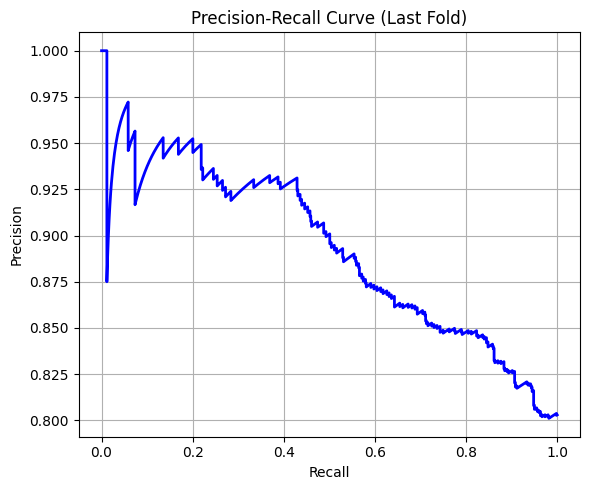

In [ ]:
# ============================================================
# ✅ Imports
# ============================================================
import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, precision_recall_curve,
    average_precision_score, auc
)
import matplotlib.pyplot as plt
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler


# ============================================================
# ✅ 1. Define the Neural Network with correct input
# ============================================================
# Determine input dimensionality correctly from data
input_dim = 14   # after dropping 'id' and 'label' columns
drop_out = 0.2

NN = tf.keras.models.Sequential([
    tf.keras.Input(shape=(input_dim,)),     # ✅ proper Sequential input layer
    tf.keras.layers.Dense(14, activation='relu'),
    tf.keras.layers.Dropout(drop_out),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dropout(drop_out),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
NN.compile(loss='binary_crossentropy',
           optimizer=optimizer,
           metrics=['accuracy', tf.keras.metrics.Precision(),
                    tf.keras.metrics.Recall(), tf.keras.metrics.AUC()])


# ✅ store weights once architecture defined
initial_weights = NN.get_weights()

def reset_weights(model, weights):
    model.set_weights(weights)


# ============================================================
# ✅ 2. Prepare Data
# ============================================================
# Keep first 15 columns + 'label'
df = df.loc[:, df.columns[:15].tolist() + ["label"]]

# Separate features/target
X = df.drop(columns=['id', 'label'])
y = df['label']

# Optional normalization (recommended for NN)
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

# Choose balancing method
balancing = 'over'  # options: 'over', 'under', or None


# ============================================================
# ✅ 3. Metric Containers
# ============================================================
accuracy_list, precision_list, recall_list = [], [], []
f1score_list, auc_list, avg_precision_list, auprc_list = [], [], [], []


# ============================================================
# ✅ 4. Cross‑Validation Loop
# ============================================================
for fold_num, (train_ids, test_ids) in enumerate(folds, 1):

    # Reset model weights
    reset_weights(NN, initial_weights)

    # Split train/test
    train_mask = df['id'].isin(train_ids.iloc[:, 0])
    test_mask  = df['id'].isin(test_ids.iloc[:, 0])

    x_train = X_scaled[train_mask]
    x_test  = X_scaled[test_mask]
    y_train = y[train_mask]
    y_test  = y[test_mask]

    # Balance training data
    if balancing == 'over':
        balancer = RandomOverSampler(random_state=42)
        x_train_bal, y_train_bal = balancer.fit_resample(x_train, y_train)
    elif balancing == 'under':
        balancer = RandomUnderSampler(random_state=42)
        x_train_bal, y_train_bal = balancer.fit_resample(x_train, y_train)
    else:
        x_train_bal, y_train_bal = x_train, y_train

    # Train
    NN.fit(x_train_bal, y_train_bal, epochs=100, batch_size=32, verbose=0)

    # Predict
    pred = NN.predict(x_test).flatten()
    binary_pred = (pred >= 0.5).astype(int)

    # Compute metrics
    accuracy = accuracy_score(y_test, binary_pred)
    precision = precision_score(y_test, binary_pred, zero_division=0)
    recall = recall_score(y_test, binary_pred, zero_division=0)
    f1 = f1_score(y_test, binary_pred, zero_division=0)
    auc_score = roc_auc_score(y_test, pred)
    precision_vals, recall_vals, _ = precision_recall_curve(y_test, pred)
    avg_precision = average_precision_score(y_test, pred)
    auprc = auc(recall_vals, precision_vals)

    # Store metrics
    accuracy_list.append(accuracy)
    precision_list.append(precision)
    recall_list.append(recall)
    f1score_list.append(f1)
    auc_list.append(auc_score)
    avg_precision_list.append(avg_precision)
    auprc_list.append(auprc)

    # Print fold summary
    print(f"Fold {fold_num} - "
          f"Acc: {accuracy:.4f}, Prec: {precision:.4f}, Rec: {recall:.4f}, "
          f"F1: {f1:.4f}, AUC: {auc_score:.4f}, AvgPrec: {avg_precision:.4f}, AUPRC: {auprc:.4f}")


# ============================================================
# ✅ 5. Mean ± Std summary
# ============================================================
def print_mean_std(values, name):
    print(f"{name:<15}: {np.mean(values):.4f} ± {np.std(values):.4f}")

print("\nAverage metrics across all folds (mean ± std):")
print_mean_std(accuracy_list, "Accuracy")
print_mean_std(precision_list, "Precision")
print_mean_std(recall_list, "Recall")
print_mean_std(f1score_list, "F1 Score")
print_mean_std(auc_list, "AUC")
print_mean_std(auprc_list, "AUPRC")


# ============================================================
# ✅ 6. PR Curve of Last Fold
# ============================================================
plt.figure(figsize=(6, 5))
plt.plot(recall_vals, precision_vals, color='blue', lw=2)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision‑Recall Curve (Last Fold)')
plt.grid(True)
plt.tight_layout()
plt.show()


#Word2Vec

In [ ]:
from google.colab import drive
import os
drive.mount('/content/gdrive')

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [ ]:
import pandas as pd
df = pd.read_csv('/content/gdrive/MyDrive/New_Repo_Data/protwv.csv')
wv_df = df.loc[:, list(df.columns[:513])]
prot_df = pd.read_csv("/content/gdrive/MyDrive/New_Repo_Data/new_emb_protT5.csv")
prot_df = prot_df.iloc[:4819,:]

In [ ]:
new_df = pd.merge(wv_df, prot_df, on='Id')
wv_df_with_label = df.loc[:, list(df.columns[:513]) + ["label"]]

In [ ]:
import tensorflow as tf

input_dim= 1536
#input_dim=512
drop_out=0.2

NN = tf.keras.models.Sequential([
    tf.keras.layers.Dense(1536,input_dim=input_dim, activation='relu'),
    tf.keras.layers.Dropout(drop_out),
    tf.keras.layers.Dense(128,input_dim=input_dim, activation='relu'),
    tf.keras.layers.Dropout(drop_out),
    tf.keras.layers.Dense(16,input_dim=input_dim, activation='relu'),
    tf.keras.layers.Dropout(drop_out),
    tf.keras.layers.Dense(1, activation='sigmoid'),
])
optimizer = tf.keras.optimizers.Adam(learning_rate = 0.001)

NN.compile(loss='binary_crossentropy', optimizer=optimizer, metrics=["accuracy", "mae", "mse"],)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
import os
import numpy as np
import torch

def load_folds(folds_dir):
    folds = []
    for fold in range(1, 6):  # Assuming 5 folds (1 to 5)
        # Define the paths for train.npy and test.npy for each fold
        train_path = os.path.join(folds_dir, f'fold_{fold}_train_ids.csv')
        test_path = os.path.join(folds_dir, f'fold_{fold}_test_ids.csv')

        # Load the train and test files
        train_ids = pd.read_csv(train_path)  # This should load the numpy array of IDs
        test_ids = pd.read_csv(test_path)
        folds.append((train_ids, test_ids))

    return folds

def store_initial_weights(model):
    # Store the initial weights
    initial_weights = model.get_weights()
    return initial_weights

def reset_weights(model, initial_weights):
    # Reset the weights to the stored initial weights
    model.set_weights(initial_weights)

initial_weights = store_initial_weights(NN)
# Example usage
folds_dir = "/content/gdrive/MyDrive/New_Repo_Data/5folds_IId"  # Update this path to your Google Drive directory
folds = load_folds(folds_dir)

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, precision_recall_curve,
    average_precision_score, auc
)
import matplotlib.pyplot as plt
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler

# Placeholder for storing fold metrics
accuracy_list, precision_list, recall_list = [], [], []
f1score_list, auc_list, avg_precision_list, auprc_list = [], [], [], []

X = new_df.drop(columns=['Id', 'label'])
#X = wv_df_with_label.drop(columns=['Id', 'label'])
y = new_df['label']
#y = wv_df_with_label['label']
# Choose your balancing method: 'smote' or 'undersample'
balancing = 'over'
# balancing = 'undersample'

for fold_num, (train_ids, test_ids) in enumerate(folds, 1):

    # Assuming reset_weights and NN, initial_weights are defined elsewhere
    # reset_weights(NN, initial_weights)

    # Split
    reset_weights(NN, initial_weights)
    print(train_ids.shape)
    print(test_ids.shape)
    x_train = X[new_df['Id'].isin(list(train_ids.iloc[:,0]))]
    x_test = X[new_df['Id'].isin(list(test_ids.iloc[:,0]))]
    y_train = y[new_df['Id'].isin(list(train_ids.iloc[:,0]))]
    y_test = y[new_df['Id'].isin(list(test_ids.iloc[:,0]))]

    # --- Data Balancing on Train only ---
    if balancing == 'over':
        #sm = SMOTE(random_state=42)
        #x_train_bal, y_train_bal = sm.fit_resample(x_train, y_train)
        oversampler = RandomOverSampler(random_state=42)
        # Apply oversampling
        x_train_bal, y_train_bal = oversampler.fit_resample(x_train, y_train) # <--- CORRECTED HERE: y_train_balr to y_train_bal
    elif balancing == 'undersample':
        rus = RandomUnderSampler(random_state=42)
        x_train_bal, y_train_bal = rus.fit_resample(x_train, y_train)
    else:
        x_train_bal, y_train_bal = x_train, y_train

    # --- Train on balanced data ---
    # The NN.fit call now correctly uses y_train_bal
    NN.fit(x_train_bal, y_train_bal, epochs=50, batch_size=32)
    pred = NN.predict(x_test)

    # Evaluate
    threshold = 0.5
    binary_predictions = (pred >= threshold).astype(int)
    accuracy = accuracy_score(y_test, binary_predictions)
    precision = precision_score(y_test, binary_predictions)
    recall = recall_score(y_test, binary_predictions)
    f1 = f1_score(y_test, binary_predictions)
    auc_score = roc_auc_score(y_test, pred)
    precision_values, recall_values, _ = precision_recall_curve(y_test, pred)
    avg_precision = average_precision_score(y_test, pred)
    auprc = auc(recall_values, precision_values)

    # Store
    accuracy_list.append(accuracy)
    precision_list.append(precision)
    recall_list.append(recall)
    f1score_list.append(f1)
    auc_list.append(auc_score)
    avg_precision_list.append(avg_precision)
    auprc_list.append(auprc)

    print(f"Fold {fold_num} - Accuracy: {accuracy:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}, F1 Score: {f1:.4f}, "
          f"AUC: {auc_score:.4f}, AUPRC: {auprc:.4f}")

def print_mean_std(metric_list, metric_name):
    print(f"{metric_name:<15}: {np.mean(metric_list):.4f} ± {np.std(metric_list):.4f}")

print("\nAverage metrics across all folds (mean ± std):")
print_mean_std(accuracy_list, "Accuracy")
print_mean_std(precision_list, "Precision")
print_mean_std(recall_list, "Recall")
print_mean_std(f1score_list, "F1 Score")
print_mean_std(auc_list, "AUC")
print_mean_std(auprc_list, "AUPRC")

(2984, 1)
(746, 1)
Epoch 1/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 8s 37ms/step - accuracy: 0.6859 - loss: 0.5798 - mae: 0.3969 - mse: 0.1991
Epoch 2/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 7s 48ms/step - accuracy: 0.8533 - loss: 0.3436 - mae: 0.2258 - mse: 0.1079
Epoch 3/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 9s 38ms/step - accuracy: 0.9254 - loss: 0.1991 - mae: 0.1246 - mse: 0.0574
Epoch 4/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 8s 50ms/step - accuracy: 0.9661 - loss: 0.0986 - mae: 0.0632 - mse: 0.0272
Epoch 5/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 9s 41ms/step - accuracy: 0.9765 - loss: 0.0644 - mae: 0.0382 - mse: 0.0174
Epoch 6/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 7s 45ms/step - accuracy: 0.9852 - loss: 0.0459 - mae: 0.0269 - mse: 0.0113
Epoch 7/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 11s 49ms/step - accuracy: 0.9878 - loss: 0.0361 - mae: 0.0230 - mse: 0.0096
Epoch 8/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 6s 37ms/step - accuracy: 0.9823 - loss: 0.0556 - mae: 0.0302 - mse: 0.0135
Epoch 9/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 12s 48ms/step - accu

#ProtT5

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [ ]:
import pandas as pd
new_df = pd.read_csv('/content/gdrive/MyDrive/New_Repo_Data/protT5_embeddings.csv')
new_df = new_df.iloc[:4819,:]
new_df.rename(columns={new_df.columns[0]: "id"}, inplace=True)

In [ ]:
new_df

,id,0,1,2,3,4,5,6,7,8,...,1015,1016,1017,1018,1019,1020,1021,1022,1023,label
0,A0A023T695,0.042693,0.124720,0.032211,-0.022437,0.040958,0.054669,-0.051775,-0.059499,-0.007926,...,-0.034986,-0.055709,-0.005761,0.046603,-0.039662,-0.047364,0.016026,0.008150,0.019522,0
1,A0A024QZV0,0.022175,0.084556,-0.004435,0.024290,-0.019009,0.048525,-0.038699,-0.066670,0.059472,...,-0.012844,0.025402,0.010749,0.009804,-0.060085,-0.064978,-0.034478,0.020194,0.041869,0
2,A0A024R240,0.063888,0.145525,0.036952,0.005269,0.019609,0.013601,-0.087395,-0.036728,-0.000637,...,-0.015352,-0.041265,-0.012034,0.050319,-0.023188,-0.019609,-0.023661,0.000675,0.022876,0
3,A0A024R2F9,-0.005953,0.035586,0.009683,0.070807,-0.000663,0.022921,-0.002470,-0.087166,0.046816,...,-0.001454,0.050997,0.004633,-0.001679,-0.061853,-0.015558,-0.042030,0.000134,-0.045054,0
4,A0A024R2L1,0.028700,0.104858,0.042660,0.015287,0.019116,0.021769,-0.021436,-0.053334,0.020576,...,-0.026001,-0.017487,0.011288,0.048748,-0.004883,-0.032762,-0.012197,-0.027160,-0.002401,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4814,P0DN78,0.017106,0.113525,0.038877,0.024763,-0.001922,0.040555,-0.025455,-0.020239,-0.035944,...,-0.028432,-0.027906,0.005450,0.020733,-0.022165,-0.029283,0.016566,-0.012306,0.003213,1
4815,P17050,0.054113,0.098839,0.032692,0.020130,-0.017451,0.061578,-0.055679,-0.066085,0.008642,...,0.005819,-0.009898,-0.008317,0.052366,-0.018849,-0.007555,-0.024101,0.016986,0.020968,0
4816,Q14738,0.078506,0.058517,0.012026,0.005436,-0.001147,0.048317,-0.048809,-0.054184,-0.017945,...,-0.019999,-0.026921,0.013905,0.059735,-0.000883,0.002936,0.023951,0.010198,0.040855,0
4817,Q6UXN9,0.017517,0.072535,0.012575,0.036436,-0.010469,0.024839,0.019931,-0.051024,0.030437,...,-0.022747,-0.010350,-0.003256,0.039078,0.016017,-0.015950,-0.042711,-0.006185,-0.001681,0


In [ ]:
import tensorflow as tf
input_dim=1024
#input_dim=512
drop_out=0.2
NN=tf.keras.models.Sequential([
    tf.keras.layers.Dense(1024,input_dim=input_dim, activation='relu'),
    tf.keras.layers.Dropout(drop_out),
    tf.keras.layers.Dense(128,input_dim=input_dim, activation='relu'),
    tf.keras.layers.Dropout(drop_out),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dropout(drop_out),
    tf.keras.layers.Dense(1, activation='sigmoid'),
    ])
optimizer = tf.keras.optimizers.Adam(learning_rate = 0.001)
NN.compile(loss='binary_crossentropy', optimizer=optimizer, metrics=["accuracy", "mae", "mse"],)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
import os
import numpy as np
import torch

def load_folds(folds_dir):
    folds = []
    for fold in range(1, 6):  # Assuming 5 folds (1 to 5)
        # Define the paths for train.npy and test.npy for each fold
        train_path = os.path.join(folds_dir, f'fold_{fold}_train_ids.csv')
        test_path = os.path.join(folds_dir, f'fold_{fold}_test_ids.csv')

        # Load the train and test files
        train_ids = pd.read_csv(train_path)  # This should load the numpy array of IDs
        test_ids = pd.read_csv(test_path)
        folds.append((train_ids, test_ids))

    return folds

def store_initial_weights(model):
    # Store the initial weights
    initial_weights = model.get_weights()
    return initial_weights

def reset_weights(model, initial_weights):
    # Reset the weights to the stored initial weights
    model.set_weights(initial_weights)

initial_weights = store_initial_weights(NN)
# Example usage
folds_dir = "/content/gdrive/MyDrive/New_Repo_Data/5folds_IId"  # Update this path to your Google Drive directory
folds = load_folds(folds_dir)

In [ ]:
new_df

,id,0,1,2,3,4,5,6,7,8,...,1015,1016,1017,1018,1019,1020,1021,1022,1023,label
0,A0A023T695,0.042693,0.124720,0.032211,-0.022437,0.040958,0.054669,-0.051775,-0.059499,-0.007926,...,-0.034986,-0.055709,-0.005761,0.046603,-0.039662,-0.047364,0.016026,0.008150,0.019522,0
1,A0A024QZV0,0.022175,0.084556,-0.004435,0.024290,-0.019009,0.048525,-0.038699,-0.066670,0.059472,...,-0.012844,0.025402,0.010749,0.009804,-0.060085,-0.064978,-0.034478,0.020194,0.041869,0
2,A0A024R240,0.063888,0.145525,0.036952,0.005269,0.019609,0.013601,-0.087395,-0.036728,-0.000637,...,-0.015352,-0.041265,-0.012034,0.050319,-0.023188,-0.019609,-0.023661,0.000675,0.022876,0
3,A0A024R2F9,-0.005953,0.035586,0.009683,0.070807,-0.000663,0.022921,-0.002470,-0.087166,0.046816,...,-0.001454,0.050997,0.004633,-0.001679,-0.061853,-0.015558,-0.042030,0.000134,-0.045054,0
4,A0A024R2L1,0.028700,0.104858,0.042660,0.015287,0.019116,0.021769,-0.021436,-0.053334,0.020576,...,-0.026001,-0.017487,0.011288,0.048748,-0.004883,-0.032762,-0.012197,-0.027160,-0.002401,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4814,P0DN78,0.017106,0.113525,0.038877,0.024763,-0.001922,0.040555,-0.025455,-0.020239,-0.035944,...,-0.028432,-0.027906,0.005450,0.020733,-0.022165,-0.029283,0.016566,-0.012306,0.003213,1
4815,P17050,0.054113,0.098839,0.032692,0.020130,-0.017451,0.061578,-0.055679,-0.066085,0.008642,...,0.005819,-0.009898,-0.008317,0.052366,-0.018849,-0.007555,-0.024101,0.016986,0.020968,0
4816,Q14738,0.078506,0.058517,0.012026,0.005436,-0.001147,0.048317,-0.048809,-0.054184,-0.017945,...,-0.019999,-0.026921,0.013905,0.059735,-0.000883,0.002936,0.023951,0.010198,0.040855,0
4817,Q6UXN9,0.017517,0.072535,0.012575,0.036436,-0.010469,0.024839,0.019931,-0.051024,0.030437,...,-0.022747,-0.010350,-0.003256,0.039078,0.016017,-0.015950,-0.042711,-0.006185,-0.001681,0


In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, precision_recall_curve,
    average_precision_score, auc
)
import matplotlib.pyplot as plt
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler

# Placeholder for storing fold metrics
accuracy_list, precision_list, recall_list = [], [], []
f1score_list, auc_list, avg_precision_list, auprc_list = [], [], [], []

X = new_df.drop(columns=['id', 'label'])
y = new_df['label']

# Choose your balancing method: 'smote' or 'undersample'
balancing = 'over'
# balancing = 'undersample'

for fold_num, (train_ids, test_ids) in enumerate(folds, 1):

    # Assuming reset_weights and NN, initial_weights are defined elsewhere
    # reset_weights(NN, initial_weights)

    # Split
    reset_weights(NN, initial_weights)
    print(train_ids.shape)
    print(test_ids.shape)
    x_train = X[new_df['id'].isin(list(train_ids.iloc[:,0]))]
    x_test = X[new_df['id'].isin(list(test_ids.iloc[:,0]))]
    y_train = y[new_df['id'].isin(list(train_ids.iloc[:,0]))]
    y_test = y[new_df['id'].isin(list(test_ids.iloc[:,0]))]

    # --- Data Balancing on Train only ---
    if balancing == 'over':
        #sm = SMOTE(random_state=42)
        #x_train_bal, y_train_bal = sm.fit_resample(x_train, y_train)
        oversampler = RandomOverSampler(random_state=42)
        # Apply oversampling
        x_train_bal, y_train_bal = oversampler.fit_resample(x_train, y_train) # <--- CORRECTED HERE: y_train_balr to y_train_bal
    elif balancing == 'undersample':
        rus = RandomUnderSampler(random_state=42)
        x_train_bal, y_train_bal = rus.fit_resample(x_train, y_train)
    else:
        x_train_bal, y_train_bal = x_train, y_train

    # --- Train on balanced data ---
    # The NN.fit call now correctly uses y_train_bal
    NN.fit(x_train_bal, y_train_bal, epochs=50, batch_size=32)
    pred = NN.predict(x_test)

    # Evaluate
    threshold = 0.5
    binary_predictions = (pred >= threshold).astype(int)
    accuracy = accuracy_score(y_test, binary_predictions)
    precision = precision_score(y_test, binary_predictions)
    recall = recall_score(y_test, binary_predictions)
    f1 = f1_score(y_test, binary_predictions)
    auc_score = roc_auc_score(y_test, pred)
    precision_values, recall_values, _ = precision_recall_curve(y_test, pred)
    avg_precision = average_precision_score(y_test, pred)
    auprc = auc(recall_values, precision_values)

    # Store
    accuracy_list.append(accuracy)
    precision_list.append(precision)
    recall_list.append(recall)
    f1score_list.append(f1)
    auc_list.append(auc_score)
    avg_precision_list.append(avg_precision)
    auprc_list.append(auprc)

    print(f"Fold {fold_num} - Accuracy: {accuracy:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}, F1 Score: {f1:.4f}, "
          f"AUC: {auc_score:.4f}, AUPRC: {auprc:.4f}")

def print_mean_std(metric_list, metric_name):
    print(f"{metric_name:<15}: {np.mean(metric_list):.4f} ± {np.std(metric_list):.4f}")

print("\nAverage metrics across all folds (mean ± std):")
print_mean_std(accuracy_list, "Accuracy")
print_mean_std(precision_list, "Precision")
print_mean_std(recall_list, "Recall")
print_mean_std(f1score_list, "F1 Score")
print_mean_std(auc_list, "AUC")
print_mean_std(auprc_list, "AUPRC")

# Plot last PR Curve



(2984, 1)
(746, 1)
Epoch 1/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.6452 - loss: 0.6277 - mae: 0.4404 - mse: 0.2189
Epoch 2/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.7586 - loss: 0.4973 - mae: 0.3318 - mse: 0.1644
Epoch 3/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 4s 29ms/step - accuracy: 0.8069 - loss: 0.4209 - mae: 0.2774 - mse: 0.1354
Epoch 4/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accuracy: 0.8409 - loss: 0.3475 - mae: 0.2332 - mse: 0.1095
Epoch 5/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.8717 - loss: 0.2940 - mae: 0.1876 - mse: 0.0905
Epoch 6/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - accuracy: 0.9005 - loss: 0.2368 - mae: 0.1506 - mse: 0.0723
Epoch 7/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.9253 - loss: 0.1869 - mae: 0.1184 - mse: 0.0556
Epoch 8/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.9422 - loss: 0.1505 - mae: 0.0957 - mse: 0.0434
Epoch 9/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - accura

#Node2vec

##Load Data

In [4]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


In [5]:
import pandas as pd
#df_emb = pd.read_csv('/content/gdrive/MyDrive/New_Repo_Data/ilearnPlus_DipeptideCompDev_features.csv')
#df_emb = pd.read_csv('/content/gdrive/MyDrive/New_Repo_Data/New_embeddings_protbert_whole_nodes.csv')
#df_emb = pd.read_csv('/content/gdrive/MyDrive/New_Repo_Data/New_embeddings_protbert_whole_nodes.csv')
df_emb = pd.read_csv('/content/gdrive/MyDrive/New_Repo_Data/protT5_embeddings.csv')

df_labels = df_emb .iloc[:4819, [0, -1]]

In [6]:
df_labels

,Id,label
0,A0A023T695,0
1,A0A024QZV0,0
2,A0A024R240,0
3,A0A024R2F9,0
4,A0A024R2L1,0
...,...,...
4814,P0DN78,1
4815,P17050,0
4816,Q14738,0
4817,Q6UXN9,0


In [7]:
# Convert both ID columns to strings (example)
df_labels['Id'] = df_labels['Id'].astype(str)
df_emb['Id'] = df_emb['Id'].astype(str)

In [8]:
order_dict = {value: index for index, value in enumerate(list(df_labels['Id']))}

def sorting_key(value):
    return (order_dict.get(value, float('inf')), value)

df_emb = df_emb.sort_values(by='Id', key=lambda x: x.map(sorting_key))

In [9]:
import networkx as nx

#graph_data = pd.read_csv('/content/gdrive/MyDrive/New_Repo_Data/new_ppi_edges_iid.csv')
#graph_data = pd.read_csv('/content/gdrive/MyDrive/New_Repo_Data/new_ppi_edges_iid_whole.csv')
# graph_data = pd.read_csv('/content/gdrive/MyDrive/Data/PPI-edges-STRING.csv')
#graph_data = pd.read_csv('/content/gdrive/MyDrive/New_Repo_Data/new_ppi_edges_string_whole.csv')
graph_data = pd.read_csv('/content/gdrive/MyDrive/New_Repo_Data/new_ppi_edges_iid.csv')

id_list = list(df_emb['Id'])

G = nx.Graph()
for id1,id2 in zip(list(graph_data.iloc[:,0]),list(graph_data.iloc[:,1])):
  #if((str(id1) in id_list) and (str(id2) in id_list)):
    G.add_edge(id1,id2)
#َAdding labeled isolated nodes
'''for node in df_emb.iloc[:, 0]:
    if node not in G.nodes():
        G.add_node(node)'''

'for node in df_emb.iloc[:, 0]:\n    if node not in G.nodes():\n        G.add_node(node)'

In [10]:
len(G.nodes())

4520

##Node To Vec

In [ ]:
!pip install node2vec

  Using cached node2vec-0.5.0-py3-none-any.whl.metadata (849 bytes)
  Using cached gensim-4.4.0-cp313-cp313-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (8.4 kB)
  Using cached numpy-1.26.4.tar.gz (15.8 MB)
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done


In [ ]:
import pandas as pd
import numpy as np
import networkx as nx
from node2vec import Node2Vec

# --- 1. Graph Setup (Assuming G is already built) ---
# ... (your existing code to define G and id_list) ...

# --- 2. Extract Node2Vec Embeddings ---
# Train the model
node2vec = Node2Vec(G, dimensions=512, walk_length=30, num_walks=200, workers=4)
model = node2vec.fit(window=10, min_count=1)

# --- 3. Align and Save ---
# Create DataFrame using model vectors
word_vectors_df = pd.DataFrame(model.wv.vectors, index=model.wv.index_to_key)

# Align the embeddings to the order in your id_list
# We cast id_list to str because index_to_key stores node labels as strings
'''aligned_df = word_vectors_df.loc[[str(node_id) for node_id in id_list]]

# Convert to numpy array
embeddings_array = aligned_df.values'''

In [ ]:
word_vectors_df

In [ ]:
'''import networkx as nx
import networkx as nx
from node2vec import Node2Vec


def node2vec(graph, dimensions=512, walk_length=5, num_walks=5, window_size=3, p=1.0, q=1.0):
    # Precompute probabilities and generate walks
    node2vec = Node2Vec(graph, dimensions=dimensions, walk_length=walk_length, num_walks=num_walks, p=p, q=q)
    model = node2vec.fit(window=window_size, min_count=1, batch_words=4,epochs=5)

    return model

# Run node2vec
model = node2vec(G)

# Get the embeddings for nodes
node_embeddings = model.wv

# Example usage: get the embedding for node 1
embedding = node_embeddings[1]
print(embedding)'''

In [ ]:
index=list(range(len(G.nodes)))
word_vectors_df = pd.DataFrame(node_embeddings.vectors,index=node_embeddings.index_to_key)

In [ ]:
node_vectors_df.columns = [f'q{i+1}' for i in range(512)]
df_emb.columns = [f'v{i+1}' for i in range(1026)]

In [ ]:
df_features = df_emb[df_emb['v1'].isin(list(G.nodes()))]

In [ ]:
#df_emb.set_index('v1', inplace=True)
new_df = df_features.join(word_vectors_df,on='v1')

In [ ]:
new_df.head()

In [ ]:
nv_vector = new_df.iloc[:,0:513]

##Neural Network

In [ ]:
import tensorflow as tf

#input_dim=1536
input_dim=512
drop_out=0.1

NN = tf.keras.models.Sequential([
    tf.keras.layers.Dense(512,input_dim=input_dim, activation='relu'),
    tf.keras.layers.Dropout(drop_out),
    tf.keras.layers.Dense(128,input_dim=input_dim, activation='relu'),
    tf.keras.layers.Dropout(drop_out),
    tf.keras.layers.Dense(16,input_dim=input_dim, activation='relu'),
    tf.keras.layers.Dropout(drop_out),
    tf.keras.layers.Dense(1, activation='sigmoid'),
])
optimizer = tf.keras.optimizers.Adam(learning_rate = 0.001)

NN.compile(loss='binary_crossentropy', optimizer=optimizer, metrics=["accuracy", "mae", "mse"],)

In [ ]:
import os
import numpy as np
import torch

def load_folds(folds_dir):
    folds = []
    for fold in range(1, 6):  # Assuming 5 folds (1 to 5)
        # Define the paths for train.npy and test.npy for each fold
        train_path = os.path.join(folds_dir, f'fold_{fold}_train_ids.csv')
        test_path = os.path.join(folds_dir, f'fold_{fold}_test_ids.csv')

        # Load the train and test files
        train_ids = pd.read_csv(train_path)  # This should load the numpy array of IDs
        test_ids = pd.read_csv(test_path)
        folds.append((train_ids, test_ids))

    return folds

def store_initial_weights(model):
    # Store the initial weights
    initial_weights = model.get_weights()
    return initial_weights

def reset_weights(model, initial_weights):
    # Reset the weights to the stored initial weights
    model.set_weights(initial_weights)

initial_weights = store_initial_weights(NN)
# Example usage
folds_dir = "/content/gdrive/MyDrive/New_Repo_Data/5folds_IId"   # Update this path to your Google Drive directory
folds = load_folds(folds_dir)

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, precision_recall_curve,
    average_precision_score, auc
)
import matplotlib.pyplot as plt
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler

# Placeholder for storing fold metrics
accuracy_list, precision_list, recall_list = [], [], []
f1score_list, auc_list, avg_precision_list, auprc_list = [], [], [], []

X = new_df.drop(columns=['v1', 'v1026'])
y = new_df['v1026']

# Choose your balancing method: 'smote' or 'undersample'
balancing = 'over'
# balancing = 'undersample'

for fold_num, (train_ids, test_ids) in enumerate(folds, 1):

    # Assuming reset_weights and NN, initial_weights are defined elsewhere
    # reset_weights(NN, initial_weights)

    # Split
    reset_weights(NN, initial_weights)
    x_train = X[new_df['v1'].isin(list(train_ids.iloc[:,0]))]
    x_test = X[new_df['v1'].isin(list(test_ids.iloc[:,0]))]
    y_train = y[new_df['v1'].isin(list(train_ids.iloc[:,0]))]
    y_test = y[new_df['v1'].isin(list(test_ids.iloc[:,0]))]

    # --- Data Balancing on Train only ---
    if balancing == 'over':
        #sm = SMOTE(random_state=42)
        #x_train_bal, y_train_bal = sm.fit_resample(x_train, y_train)
        oversampler = RandomOverSampler(random_state=42)
        # Apply oversampling
        x_train_bal, y_train_bal = oversampler.fit_resample(x_train, y_train) # <--- CORRECTED HERE: y_train_balr to y_train_bal
    elif balancing == 'undersample':
        rus = RandomUnderSampler(random_state=42)
        x_train_bal, y_train_bal = rus.fit_resample(x_train, y_train)
    else:
        x_train_bal, y_train_bal = x_train, y_train

    # --- Train on balanced data ---
    # The NN.fit call now correctly uses y_train_bal
    NN.fit(x_train_bal, y_train_bal, epochs=50, batch_size=32)
    pred = NN.predict(x_test)

    # Evaluate
    threshold = 0.5
    binary_predictions = (pred >= threshold).astype(int)
    accuracy = accuracy_score(y_test, binary_predictions)
    precision = precision_score(y_test, binary_predictions)
    recall = recall_score(y_test, binary_predictions)
    f1 = f1_score(y_test, binary_predictions)
    auc_score = roc_auc_score(y_test, pred)
    precision_values, recall_values, _ = precision_recall_curve(y_test, pred)
    avg_precision = average_precision_score(y_test, pred)
    auprc = auc(recall_values, precision_values)

    # Store
    accuracy_list.append(accuracy)
    precision_list.append(precision)
    recall_list.append(recall)
    f1score_list.append(f1)
    auc_list.append(auc_score)
    avg_precision_list.append(avg_precision)
    auprc_list.append(auprc)

    print(f"Fold {fold_num} - Accuracy: {accuracy:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}, F1 Score: {f1:.4f}, "
          f"AUC: {auc_score:.4f}, Avg Precision: {avg_precision:.4f}, AUPRC: {auprc:.4f}")

def print_mean_std(metric_list, metric_name):
    print(f"{metric_name:<15}: {np.mean(metric_list):.4f} ± {np.std(metric_list):.4f}")

print("\nAverage metrics across all folds (mean ± std):")
print_mean_std(accuracy_list, "Accuracy")
print_mean_std(precision_list, "Precision")
print_mean_std(recall_list, "Recall")
print_mean_std(f1score_list, "F1 Score")
print_mean_std(auc_list, "AUC")
print_mean_std(auprc_list, "AUPRC")

# Plot last PR Curve

